# Credit Risk and Fraud Analytics
## Trimester 1 Applied Data Science Project

**Business setting:** A fictional digital lending company wants to understand loan repayment risk, review its past loan applications, and spot patterns linked with suspicious transactions.

**Main questions**
1. Which applicant and loan features are related to payment difficulty?
2. How good is a simple first credit-risk model at ranking applicants?
3. What do previous loan records and repayment history tell the operations team?
4. Which transaction patterns deserve extra fraud review?
5. How can the findings be translated into basic portfolio and technology controls?

> **Important:** Every row in this project is synthetic and generated by this notebook. It does not represent real customers, a real bank, or a production credit model. All risk drivers and transaction labels are simulated for learning.

### Topics covered
Python, Pandas, NumPy, data quality checks, probability, descriptive statistics, outliers, correlation, basic linear algebra, logistic regression, train/test split, model metrics, data visualization, expected credit loss, operations reporting, and fraud monitoring.

### How to run
Run the notebook from top to bottom. The first data-generation section creates the CSV files in the project's `data` folder using a fixed random seed. It can be run again to recreate the same datasets. All charts are made in Python and saved in `figures` for the report.

In [1]:
# ==============================================================================
# STEP 1: ENVIRONMENT CONFIGURATION & REPRODUCIBILITY SETUP
# ==============================================================================

# Core standard library imports
from pathlib import Path

# Scientific computing, numerical arrays, and data manipulation
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical hypothesis testing (two-sample unequal variance test)
from scipy.stats import ttest_ind

# Scikit-learn: dataset splitting, feature normalization, and classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Evaluation metrics for imbalanced binary credit classification
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

# ------------------------------------------------------------------------------
# Directory Path Resolution: Ensure cross-platform portability
# ------------------------------------------------------------------------------
# Candidate root directories across local IDE, Docker, and Colab environments
possible_roots = [
    Path.cwd(), 
    Path.cwd() / "Credit_Risk_Trimester1_Project", 
    Path("/mnt/data/Credit_Risk_Trimester1_Project")
]
# Select the first root containing existing data, or default to current working directory
BASE_DIR = next((p for p in possible_roots if (p / "data").exists()), Path.cwd())
DATA_DIR = BASE_DIR / "data"
FIGURE_DIR = BASE_DIR / "figures"

# Ensure output directories exist before data generation or plotting
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------------------------
# Reproducibility & Visualization Styling
# ------------------------------------------------------------------------------
SEED = 42
rng = np.random.default_rng(SEED)  # NumPy Generator for deterministic pseudo-random draws
sns.set_theme(style="whitegrid", context="notebook")  # Professional publication styling

print("Project folder:", BASE_DIR.resolve())
print("Random seed:", SEED)
print("Debug level: INFO - show sizes, missing values and simple checks during the run.")


Project folder: /mnt/data/Credit_Risk_Trimester1_Project
Random seed: 42
Debug level: INFO - show sizes, missing values and simple checks during the run.


## 1. Create the synthetic datasets

The project uses four related datasets:

- `application_data.csv`: 20,000 current loan applications with repayment outcome.
- `previous_application.csv`: historical loan applications and decisions.
- `repayment_history.csv`: six instalment records per current loan.
- `transactions.csv`: transaction records with a simulated fraud label.

The generator uses realistic-looking ranges and clear relationships, but it is not a financial model of any real population. A fixed seed makes the data reproducible. A few missing values and high-value observations are included on purpose so that data checks are meaningful.

In [2]:
# ==============================================================================
# STEP 2: SYNTHETIC DATA GENERATION ENGINE
# Generates 4 interconnected datasets representing a retail banking ecosystem:
# 1. Primary Applications (at credit decision time)
# 2. Historical Applications (bureau & internal history)
# 3. Repayment History (post-disbursement performance tracking)
# 4. Digital Transactions (fraud detection telemetry)
# ==============================================================================

# Define dataset scale parameters
N_APPLICANTS = 20_000      # Primary loan applicant volume
N_TRANSACTIONS = 50_000    # Digital transaction monitoring records
N_INSTALLMENTS = 6         # Six post-disbursement monthly payment cycles per loan

# ------------------------------------------------------------------------------
# 2.1 Demographic & Employment Attributes
# ------------------------------------------------------------------------------
# Unique 6-digit applicant primary key
applicant_id = np.arange(100001, 100001 + N_APPLICANTS)

# Application submission dates spread uniformly across a 3-year window (2023-2025)
application_dates = pd.to_datetime("2023-01-01") + pd.to_timedelta(
    rng.integers(0, 1095, N_APPLICANTS), unit="D"
)

# Applicant age: Working adult population between 21 and 70 years
age = rng.integers(21, 71, N_APPLICANTS)

# Geographic branch regions with empirical retail banking market shares
region = rng.choice(
    ["North", "South", "East", "West", "Central"], 
    N_APPLICANTS,
    p=[0.24, 0.22, 0.16, 0.20, 0.18]
)

# Education attainment distribution
education = rng.choice(
    ["School", "Graduate", "Postgraduate", "Other"], 
    N_APPLICANTS,
    p=[0.18, 0.49, 0.23, 0.10]
)

# Employment classification: majority full-time, with self-employed and contract cohorts
employment_status = rng.choice(
    ["Full-time", "Self-employed", "Contract", "Unemployed"], 
    N_APPLICANTS,
    p=[0.62, 0.15, 0.17, 0.06]
)

# ------------------------------------------------------------------------------
# 2.2 Financial Profile: Income, Score, Debt & Loan Terms
# ------------------------------------------------------------------------------
# Income modeled via log-normal distribution to capture real-world right skewness
monthly_income_true = np.clip(
    rng.lognormal(mean=np.log(52_000), sigma=0.48, size=N_APPLICANTS), 
    15_000, 250_000
)

# Adjust monthly income based on employment stability multipliers
monthly_income_true *= np.select(
    [employment_status == "Self-employed", employment_status == "Contract", employment_status == "Unemployed"],
    [1.08, 0.78, 0.42], 
    default=1.0
)
# Constrain income to realistic retail banking limits (INR 8,000 - 300,000)
monthly_income_true = np.clip(monthly_income_true, 8_000, 300_000)

# Work tenure: correlated with age, bounded by working lifespan (age - 18)
employment_years_true = np.clip(rng.normal((age - 20) * 0.43, 3.8), 0, np.maximum(age - 18, 0))

# Credit bureau score (300 to 850 scale): Higher for affluent applicants, penalized for unemployment
credit_score_true = np.clip(
    rng.normal(675 + (monthly_income_true / 50_000 - 1) * 8 - (employment_status == "Unemployed") * 35, 57),
    300, 850
)

# Existing monthly debt obligations: Beta(2, 8) distribution ensures moderate baseline debt
existing_debt_true = monthly_income_true * rng.beta(2, 8, N_APPLICANTS)

# Loan tenure options (standard amortization terms from 1 to 5 years)
loan_term_months = rng.choice([12, 24, 36, 48, 60], N_APPLICANTS, p=[0.10, 0.16, 0.34, 0.20, 0.20])

# Requested loan principal: typically 2.5x to 9.0x monthly gross earnings
loan_amount_true = monthly_income_true * rng.uniform(2.5, 9.0, N_APPLICANTS)

# Inject synthetic high-exposure outliers (~1.2% of applications) to test robust IQR handling
large_loan_rows = rng.choice(N_APPLICANTS, size=int(N_APPLICANTS * 0.012), replace=False)
loan_amount_true[large_loan_rows] *= rng.uniform(1.8, 2.8, len(large_loan_rows))
loan_amount_true = np.clip(loan_amount_true, 20_000, 1_500_000)

# Risk-based interest pricing: lower credit scores incur higher interest rate margins
interest_rate_true = np.clip(9 + (680 - credit_score_true) * 0.035 + rng.normal(0, 1.8, N_APPLICANTS), 6, 29)

# Loan stated purpose distribution
loan_purpose = rng.choice(
    ["Personal", "Vehicle", "Home improvement", "Education", "Medical", "Small business"],
    N_APPLICANTS, 
    p=[0.35, 0.17, 0.16, 0.10, 0.10, 0.12]
)

# ------------------------------------------------------------------------------
# 2.3 Financial Amortization Formula & Derived Exposure Metrics
# Standard annuity formula: EMI = P * r * (1+r)^n / ((1+r)^n - 1)
# ------------------------------------------------------------------------------
monthly_rate_true = interest_rate_true / 100 / 12
monthly_installment_true = loan_amount_true * monthly_rate_true / (1 - (1 + monthly_rate_true) ** (-loan_term_months))

# Debt-to-Income (DTI) and Loan-to-Annual-Income leverage ratios
dti_true = (existing_debt_true + monthly_installment_true) / monthly_income_true
loan_to_annual_income_true = loan_amount_true / (monthly_income_true * 12)

# ------------------------------------------------------------------------------
# 2.4 Historical Loan Applications & Prior Delinquencies
# ------------------------------------------------------------------------------
# Each applicant has 0 to 4 prior application records (Poisson distribution mean=1.25)
previous_counts = np.clip(rng.poisson(1.25, N_APPLICANTS), 0, 4)
previous_owner_idx = np.repeat(np.arange(N_APPLICANTS), previous_counts)
N_PREVIOUS = len(previous_owner_idx)

# Historical application unique identifier
previous_id = np.arange(500001, 500001 + N_PREVIOUS)

# Historical application timestamps occur prior to current application
previous_dates = application_dates[previous_owner_idx] - pd.to_timedelta(
    rng.integers(30, 1600, N_PREVIOUS), unit="D"
)
previous_loan_amount = np.clip(
    monthly_income_true[previous_owner_idx] * rng.uniform(1.5, 8.0, N_PREVIOUS), 
    5_000, 1_000_000
)

# Probability of past delinquency linked to credit score and previous debt burden
late_probability = 1 / (1 + np.exp(-np.clip(
    -3.4 + (675 - credit_score_true[previous_owner_idx]) * 0.007
    + (existing_debt_true[previous_owner_idx] / monthly_income_true[previous_owner_idx]) * 1.6,
    -15, 15
)))
previous_late = rng.random(N_PREVIOUS) < late_probability

# Days Past Due (DPD): delinquents draw 30-120 days; non-delinquents draw minimal delay
previous_dpd = np.where(previous_late, rng.integers(30, 121, N_PREVIOUS), rng.choice([0, 0, 0, 1, 5, 12], N_PREVIOUS))

# Historical underwriting decision: delinquents have much higher refusal rates
previous_status = []
for is_late in previous_late:
    if is_late:
        previous_status.append(rng.choice(["Approved", "Cancelled", "Refused", "Unused offer"], p=[0.40, 0.14, 0.36, 0.10]))
    else:
        previous_status.append(rng.choice(["Approved", "Cancelled", "Refused", "Unused offer"], p=[0.68, 0.15, 0.09, 0.08]))

# Construct historical applications dataframe
previous_applications = pd.DataFrame({
    "previous_application_id": previous_id,
    "applicant_id": applicant_id[previous_owner_idx],
    "application_date": pd.to_datetime(previous_dates).strftime("%Y-%m-%d"),
    "previous_loan_amount": previous_loan_amount.round(2),
    "previous_status": previous_status,
    "days_past_due": previous_dpd,
    "previous_interest_rate_pct": np.clip(rng.normal(15, 3, N_PREVIOUS), 6, 30).round(2)
})

# Aggregate count of prior 30+ DPD delinquency incidents per applicant
previous_delinquency_count = (
    previous_applications.assign(late30=(previous_applications["days_past_due"] >= 30).astype(int))
    .groupby("applicant_id")["late30"].sum()
    .reindex(applicant_id, fill_value=0).to_numpy()
)

# ------------------------------------------------------------------------------
# 2.5 Current Loan Default Simulation (Target Label Generation)
# Simulated via latent logistic model using strictly pre-decision application features
# ------------------------------------------------------------------------------
log_odds_default = (
    -2.85                                            # Base calibration intercept (~10% default rate)
    + (665 - credit_score_true) * 0.012              # Lower credit score increases default log-odds
    + (dti_true - 0.30) * 5.5                        # Elevated debt-to-income increases financial stress
    + previous_delinquency_count * 0.52              # Past delinquency history strongly predicts recurrence
    + (loan_to_annual_income_true - 0.45) * 1.5      # High principal-to-income increases burden
    + (employment_status == "Self-employed") * 0.16   # Income volatility penalty
    + (employment_status == "Unemployed") * 0.55      # Acute cash-flow impairment
    + (age < 25) * 0.16                              # Early-career liquidity vulnerability
)
default_probability_true = 1 / (1 + np.exp(-np.clip(log_odds_default, -15, 15)))
target_default = (rng.random(N_APPLICANTS) < default_probability_true).astype(int)

# ------------------------------------------------------------------------------
# 2.6 Assembly of Primary Applications Dataset & Controlled Missingness Injection
# ------------------------------------------------------------------------------
applications = pd.DataFrame({
    "applicant_id": applicant_id,
    "application_date": pd.to_datetime(application_dates).strftime("%Y-%m-%d"),
    "age": age,
    "region": region,
    "education_level": education,
    "employment_status": employment_status,
    "employment_years": employment_years_true.round(1),
    "monthly_income": monthly_income_true.round(2),
    "credit_score": credit_score_true.round(0),
    "existing_monthly_debt": existing_debt_true.round(2),
    "loan_amount": loan_amount_true.round(2),
    "loan_term_months": loan_term_months,
    "interest_rate_pct": interest_rate_true.round(2),
    "loan_purpose": loan_purpose,
    "previous_delinquency_count": previous_delinquency_count,
    "target_default": target_default
})

# Inject realistic missing values (MCAR/MAR) to evaluate student data-cleaning workflows
for col, missing_rate in {"monthly_income": 0.025, "credit_score": 0.020, "employment_years": 0.045}.items():
    missing_idx = rng.choice(N_APPLICANTS, size=int(N_APPLICANTS * missing_rate), replace=False)
    applications.loc[missing_idx, col] = np.nan

# ------------------------------------------------------------------------------
# 2.7 Post-Disbursement Repayment History (Portfolio Tracking)
# 6 monthly payment records per loan to monitor delinquency progression
# ------------------------------------------------------------------------------
owner_rows = np.repeat(np.arange(N_APPLICANTS), N_INSTALLMENTS)
installment_number = np.tile(np.arange(1, N_INSTALLMENTS + 1), N_APPLICANTS)
owner_default = target_default[owner_rows]
random_draw = rng.random(len(owner_rows))

# Defaulters have a much higher likelihood of late payment (42% vs 10%)
late_cutoff = np.where(owner_default == 1, 0.42, 0.10)
late_flag = random_draw < late_cutoff
dpd_values = np.zeros(len(owner_rows), dtype=int)
late_idx = np.where(late_flag)[0]
dpd_values[late_idx] = rng.choice([3, 12, 24, 35, 50, 75], len(late_idx), p=[0.12, 0.18, 0.20, 0.20, 0.18, 0.12])

# Severe delinquencies (60+ DPD) can result in a fully missed instalment
missed = (owner_default == 1) & (dpd_values >= 60) & (rng.random(len(owner_rows)) < 0.30)
installment_amount = monthly_installment_true[owner_rows]
amount_paid = np.where(missed, 0, installment_amount)
repayment_status = np.where(
    missed, "Missed", 
    np.where(dpd_values == 0, "On time", np.where(dpd_values < 30, "Late 1-29 days", "Late 30+ days"))
)
repayment_dates = application_dates[owner_rows] + pd.to_timedelta(30 * installment_number, unit="D")

repayment_history = pd.DataFrame({
    "applicant_id": applicant_id[owner_rows],
    "installment_number": installment_number,
    "installment_date": pd.to_datetime(repayment_dates).strftime("%Y-%m-%d"),
    "amount_due": installment_amount.round(2),
    "amount_paid": amount_paid.round(2),
    "days_past_due": dpd_values,
    "payment_status": repayment_status
})

# ------------------------------------------------------------------------------
# 2.8 Digital Transaction Fraud Telemetry
# Synthesizes 50,000 digital banking events with channel and behavioral fraud signals
# ------------------------------------------------------------------------------
transaction_owner = rng.integers(0, N_APPLICANTS, N_TRANSACTIONS)
transaction_dates = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, N_TRANSACTIONS), unit="D")
transaction_amount = np.clip(rng.lognormal(np.log(2_400), 0.95, N_TRANSACTIONS), 100, 100_000)
transaction_channel = rng.choice(
    ["Card present", "Online", "Mobile", "ATM", "Bank transfer"], 
    N_TRANSACTIONS,
    p=[0.31, 0.29, 0.22, 0.08, 0.10]
)
merchant_category = rng.choice(
    ["Groceries", "Fuel", "Electronics", "Travel", "Digital goods", "Dining", "Other"], 
    N_TRANSACTIONS,
    p=[0.22, 0.12, 0.12, 0.10, 0.09, 0.17, 0.18]
)
is_international = (rng.random(N_TRANSACTIONS) < 0.075).astype(int)  # 7.5% international rate
new_device = (rng.random(N_TRANSACTIONS) < 0.055).astype(int)        # 5.5% new device logins
transaction_hour = rng.integers(0, 24, N_TRANSACTIONS)

# Latent fraud log-odds model: elevated by digital channels, foreign IPs, new devices, and midnight hours
log_odds_fraud = (
    -4.80
    + (np.isin(transaction_channel, ["Online", "Mobile", "Bank transfer"])) * 0.55
    + is_international * 0.95
    + new_device * 1.05
    + (transaction_hour < 5) * 0.38
    + (transaction_amount > 15_000) * 0.50
    + (np.isin(merchant_category, ["Electronics", "Digital goods"])) * 0.25
)
fraud_probability_true = 1 / (1 + np.exp(-np.clip(log_odds_fraud, -15, 15)))
target_fraud = (rng.random(N_TRANSACTIONS) < fraud_probability_true).astype(int)

transactions = pd.DataFrame({
    "transaction_id": np.arange(900001, 900001 + N_TRANSACTIONS),
    "applicant_id": applicant_id[transaction_owner],
    "transaction_date": pd.to_datetime(transaction_dates).strftime("%Y-%m-%d"),
    "transaction_amount": transaction_amount.round(2),
    "channel": transaction_channel,
    "merchant_category": merchant_category,
    "is_international": is_international,
    "new_device": new_device,
    "transaction_hour": transaction_hour,
    "target_fraud": target_fraud
})

# ------------------------------------------------------------------------------
# 2.9 Persist Generated Datasets to CSV Disk Storage
# ------------------------------------------------------------------------------
applications.to_csv(DATA_DIR / "application_data.csv", index=False)
previous_applications.to_csv(DATA_DIR / "previous_application.csv", index=False)
repayment_history.to_csv(DATA_DIR / "repayment_history.csv", index=False)
transactions.to_csv(DATA_DIR / "transactions.csv", index=False)

# ------------------------------------------------------------------------------
# 2.10 Generate and Persist Data Dictionary
# ------------------------------------------------------------------------------
dictionary_rows = [
    ("application_data.csv", "applicant_id", "Synthetic applicant key", "Identifier only; not a model feature."),
    ("application_data.csv", "target_default", "1 = payment difficulty; 0 = no payment difficulty", "Simulated outcome label."),
    ("application_data.csv", "credit_score", "Simulated credit score between 300 and 850", "Higher generally represents stronger credit history in this synthetic data."),
    ("application_data.csv", "monthly_income", "Approximate monthly income in INR", "Synthetic amount; some values are missing by design."),
    ("application_data.csv", "existing_monthly_debt", "Existing monthly debt payments in INR", "Used when estimating total monthly debt burden."),
    ("application_data.csv", "loan_amount", "Requested loan principal in INR", "Contains some high-value observations for outlier practice."),
    ("application_data.csv", "previous_delinquency_count", "Number of past applications with 30+ days past due", "Derived from previous_application.csv."),
    ("previous_application.csv", "previous_status", "Approved, Cancelled, Refused, or Unused offer", "Historical application decision."),
    ("previous_application.csv", "days_past_due", "Days a previous payment was overdue", "Synthetic historical repayment signal."),
    ("repayment_history.csv", "payment_status", "On time, Late, or Missed category", "Post-loan monitoring data; not used as a pre-loan model feature."),
    ("transactions.csv", "target_fraud", "1 = suspicious/fraud-labelled transaction; 0 = other", "Synthetic fraud label for practice only."),
    ("transactions.csv", "new_device", "1 = device differs from the usual device; 0 = not flagged", "One simulated fraud-monitoring signal."),
    ("transactions.csv", "is_international", "1 = international transaction; 0 = domestic", "One simulated transaction attribute."),
    ("transactions.csv", "transaction_hour", "Hour of transaction from 0 to 23", "Used to compare transaction patterns."),
]
pd.DataFrame(dictionary_rows, columns=["file", "column", "meaning", "notes"]).to_csv(DATA_DIR / "data_dictionary.csv", index=False)

print("[PASS] Synthetic data created with seed", SEED)
for file_name, frame in [
    ("application_data.csv", applications),
    ("previous_application.csv", previous_applications),
    ("repayment_history.csv", repayment_history),
    ("transactions.csv", transactions),
]:
    print(f"[INFO] {file_name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
print("[INFO] Current-loan payment difficulty rate:", round(applications["target_default"].mean() * 100, 2), "%")
print("[INFO] Synthetic transaction fraud rate:", round(transactions["target_fraud"].mean() * 100, 2), "%")


[PASS] Synthetic data created with seed 42
[INFO] application_data.csv: 20,000 rows x 16 columns
[INFO] previous_application.csv: 24,831 rows x 7 columns
[INFO] repayment_history.csv: 120,000 rows x 7 columns
[INFO] transactions.csv: 50,000 rows x 10 columns
[INFO] Current-loan payment difficulty rate: 15.82 %
[INFO] Synthetic transaction fraud rate: 1.74 %


## 2. Load the saved files and check the data

We now load the CSV files back from disk. This is a useful check that the files were saved in the expected format. The `target_default` field is the main outcome for current loans. The fraud analysis uses its separate `target_fraud` field.

In [3]:
# ==============================================================================
# STEP 3: DATA INGESTION & DATASET PREVIEWS
# Read persisted CSV files into pandas DataFrames, parsing ISO datetime fields.
# ==============================================================================

# Ingest primary application data, historical applications, repayments, and transactions
applications = pd.read_csv(DATA_DIR / "application_data.csv", parse_dates=["application_date"])
previous_applications = pd.read_csv(DATA_DIR / "previous_application.csv", parse_dates=["application_date"])
repayment_history = pd.read_csv(DATA_DIR / "repayment_history.csv", parse_dates=["installment_date"])
transactions = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["transaction_date"])
data_dictionary = pd.read_csv(DATA_DIR / "data_dictionary.csv")

# Display initial records to inspect schemas and formatting
print("Application data preview:")
display(applications.head())

print("\nPrevious applications preview:")
display(previous_applications.head())

print("\nTransaction data preview:")
display(transactions.head())


Application data preview:


,applicant_id,application_date,age,region,education_level,employment_status,employment_years,monthly_income,credit_score,existing_monthly_debt,loan_amount,loan_term_months,interest_rate_pct,loan_purpose,previous_delinquency_count,target_default
0,100001,2023-04-08,22,West,Graduate,Contract,0.0,47588.47,611.0,11845.69,265788.75,48,11.55,Vehicle,0,1
1,100002,2025-04-27,57,Central,School,Self-employed,15.5,54579.90,618.0,23712.55,170141.39,36,11.33,Personal,0,0
2,100003,2024-12-17,31,North,School,Contract,7.2,43804.03,616.0,10062.44,263624.81,36,7.23,Vehicle,0,0
3,100004,2024-04-25,56,South,School,Unemployed,13.4,18459.56,617.0,3377.98,61789.32,12,11.36,Education,0,1
4,100005,2024-04-19,49,East,Other,Full-time,11.4,35189.26,725.0,5575.92,164048.03,36,6.72,Education,0,0



Previous applications preview:


,previous_application_id,applicant_id,application_date,previous_loan_amount,previous_status,days_past_due,previous_interest_rate_pct
0,500001,100001,2021-10-22,222987.71,Approved,5,17.42
1,500002,100002,2024-06-13,261488.56,Unused offer,0,9.86
2,500003,100002,2023-03-10,101058.02,Approved,0,18.45
3,500004,100002,2021-04-02,255632.40,Cancelled,12,19.16
4,500005,100003,2020-10-24,266320.35,Approved,12,18.41



Transaction data preview:


,transaction_id,applicant_id,transaction_date,transaction_amount,channel,merchant_category,is_international,new_device,transaction_hour,target_fraud
0,900001,115552,2025-09-01,903.16,Card present,Fuel,0,0,8,0
1,900002,103907,2025-01-02,17927.42,Card present,Digital goods,0,0,21,0
2,900003,116699,2025-02-23,4836.75,Card present,Other,0,0,20,0
3,900004,117796,2025-06-18,10777.22,Mobile,Dining,0,0,12,0
4,900005,119171,2025-12-04,4743.88,Online,Groceries,0,0,2,0


In [4]:
# ==============================================================================
# STEP 4: DATA INTEGRITY & AUDIT CHECKS
# Validate shape, row uniqueness, missing counts, and primary key integrity.
# ==============================================================================

def basic_data_check(name, frame, key_column=None):
    """
    Performs baseline structural validation on a given DataFrame.
    Prints dimensions, duplicate row count, total nulls, and primary key uniqueness.
    """
    print(f"\n[CHECK] {name}")
    print("Shape:", frame.shape)
    print("Duplicate rows:", int(frame.duplicated().sum()))
    print("Total missing cells:", int(frame.isna().sum().sum()))
    if key_column:
        print("Duplicate key values:", int(frame[key_column].duplicated().sum()))

# Execute integrity checks across all 4 production tables
basic_data_check("Applications", applications, "applicant_id")
basic_data_check("Previous applications", previous_applications, "previous_application_id")
basic_data_check("Repayment history", repayment_history)
basic_data_check("Transactions", transactions, "transaction_id")

# Programmatic validation assertions: ensure no primary key duplicates or label corruption
assert applications["applicant_id"].is_unique, "Applicant ID should be unique in application data."
assert set(applications["target_default"].dropna().unique()).issubset({0, 1}), "Target must be 0 or 1."
assert set(transactions["target_fraud"].dropna().unique()).issubset({0, 1}), "Fraud label must be 0 or 1."
print("\n[PASS] Key columns and target values passed the basic checks.")



[CHECK] Applications
Shape: (20000, 16)
Duplicate rows: 0
Total missing cells: 1800
Duplicate key values: 0

[CHECK] Previous applications
Shape: (24831, 7)
Duplicate rows: 0
Total missing cells: 0
Duplicate key values: 0

[CHECK] Repayment history
Shape: (120000, 7)
Duplicate rows: 0
Total missing cells: 0

[CHECK] Transactions
Shape: (50000, 10)
Duplicate rows: 0
Total missing cells: 0
Duplicate key values: 0

[PASS] Key columns and target values passed the basic checks.


## 3. Missing values and data quality

Missing values are measured before they are handled. In the EDA tables, we keep the original values visible so the data issue is not hidden. For the first machine-learning model only, missing numeric inputs are filled with the median calculated from the training data. This is a simple and explainable baseline. We do not delete unusual loan records only because they are high.

,missing_count,missing_percent
employment_years,900,4.5
monthly_income,500,2.5
credit_score,400,2.0
applicant_id,0,0.0
region,0,0.0
age,0,0.0
employment_status,0,0.0
application_date,0,0.0
education_level,0,0.0
existing_monthly_debt,0,0.0


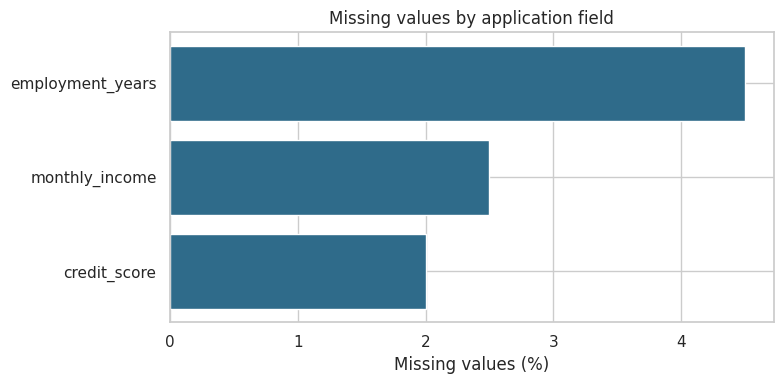

In [5]:
# ==============================================================================
# STEP 5: MISSING VALUE PROFILING & VISUALIZATION
# Identify variables with missing entries and quantify missingness percentages.
# ==============================================================================

# Compute total missing values and percentage of rows affected per column
missing_summary = applications.isna().sum().to_frame("missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(applications) * 100).round(2)
missing_summary = missing_summary.sort_values("missing_percent", ascending=False)
display(missing_summary.head(10))

# Filter to only features exhibiting missing values (> 0%) for visual plotting
missing_plot = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_percent")
if not missing_plot.empty:
    plt.figure(figsize=(8, 4))
    # Horizontal bar plot displaying missingness ratios
    plt.barh(missing_plot.index, missing_plot["missing_percent"], color="#2F6B8A")
    plt.xlabel("Missing values (%)")
    plt.title("Missing values by application field")
    plt.tight_layout()
    # Save high-resolution chart artifact for stakeholder documentation
    plt.savefig(FIGURE_DIR / "missing_values.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("No missing values were found.")


## 4. Add a few business measures

Three useful measures are created from fields available at application time:

- **Monthly instalment:** estimated monthly loan payment from principal, interest rate and term.
- **Debt-to-income ratio (DTI):** existing debt plus the new instalment, divided by monthly income.
- **Loan-to-annual-income ratio:** requested loan amount divided by annual income.

These measures help compare applicants of different income levels. They are estimates based on the simulated fields, not real underwriting rules.

In [6]:
# ==============================================================================
# STEP 6: FEATURE ENGINEERING (DERIVED FINANCIAL METRICS)
# Engineer business-driven financial ratios to evaluate borrower leverage:
# 1. Monthly Instalment (EMI): True amortized monthly payment
# 2. Debt-to-Income (DTI): Total debt service obligation relative to income
# 3. Loan-to-Annual-Income: Principal exposure relative to earning power
# 4. Net Disposable Income: Liquidity buffer remaining after debt payments
# ==============================================================================

# Work on an isolated DataFrame copy to preserve original raw table unmodified
app = applications.copy()

# Monthly interest rate factor
monthly_rate = app["interest_rate_pct"] / 100 / 12

# Standard amortization formula: EMI = P * r / (1 - (1 + r)^(-n))
app["monthly_installment"] = app["loan_amount"] * monthly_rate / (1 - (1 + monthly_rate) ** (-app["loan_term_months"]))

# Debt-to-Income (DTI) ratio: (Existing Debt + New EMI) / Monthly Income
app["debt_to_income_ratio"] = (app["existing_monthly_debt"] + app["monthly_installment"]) / app["monthly_income"]

# Loan-to-Annual-Income ratio: Loan Amount / (12 * Monthly Income)
app["loan_to_annual_income_ratio"] = app["loan_amount"] / (app["monthly_income"] * 12)

# Net Disposable Cashflow: Monthly Income - Existing Debt - New EMI
app["income_after_debt_and_installment"] = app["monthly_income"] - app["existing_monthly_debt"] - app["monthly_installment"]

# Display summary statistics of newly engineered financial features
print("New measure checks:")
display(app[["monthly_installment", "debt_to_income_ratio", "loan_to_annual_income_ratio", "income_after_debt_and_installment"]].describe().round(2))
print("[INFO] DTI is missing where monthly income is missing; this is expected.")


New measure checks:


,monthly_installment,debt_to_income_ratio,loan_to_annual_income_ratio,income_after_debt_and_installment
count,20000.00,19500.00,19500.00,19500.00
mean,11460.35,0.41,0.49,32229.18
std,10480.30,0.18,0.17,21077.76
min,559.33,0.06,0.21,-79785.34
25%,5117.88,0.28,0.34,17967.15
50%,8428.27,0.38,0.48,27864.14
75%,13946.72,0.50,0.62,41622.87
max,133441.65,2.28,1.99,194177.18


[INFO] DTI is missing where monthly income is missing; this is expected.


## 5. Target distribution and imbalance

The default label is not expected to be evenly split. We compare both counts and percentages, then calculate the ratio of the larger class to the smaller class. This matters because a model can appear accurate simply by predicting the majority class.

,count,percent
No payment difficulty (0),16836,84.18
Payment difficulty (1),3164,15.82


Class imbalance ratio (majority:minority): 5.3:1
Overall payment difficulty rate: 15.82%


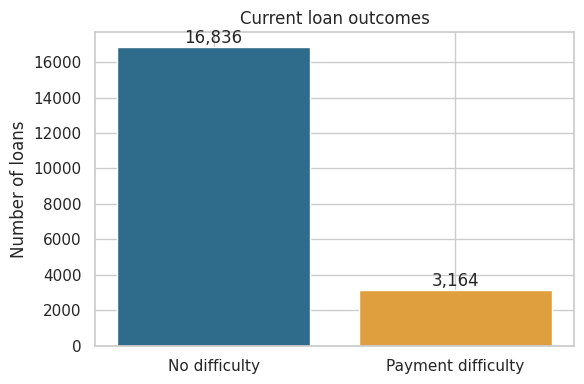

In [7]:
# ==============================================================================
# STEP 7: TARGET CLASS DISTRIBUTION & IMBALANCE QUANTIFICATION
# Evaluate default incidence (Target=1: Payment Difficulty vs Target=0: Normal).
# Quantify the majority-to-minority imbalance ratio to guide modeling strategy.
# ==============================================================================

# Absolute counts and relative proportions of target default outcomes
target_counts = app["target_default"].value_counts().sort_index()
target_percent = app["target_default"].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({"count": target_counts, "percent": target_percent.round(2)})
target_summary.index = ["No payment difficulty (0)", "Payment difficulty (1)"]
display(target_summary)

# Quantify exact class imbalance ratio
majority_count = int(target_counts.max())
minority_count = int(target_counts.min())
imbalance_ratio = majority_count / minority_count
print(f"Class imbalance ratio (majority:minority): {imbalance_ratio:.1f}:1")
print(f"Overall payment difficulty rate: {app['target_default'].mean() * 100:.2f}%")

# Visualize the target distribution with bar chart annotations
plt.figure(figsize=(6, 4))
labels = ["No difficulty", "Payment difficulty"]
values = [int((app["target_default"] == 0).sum()), int((app["target_default"] == 1).sum())]
bars = plt.bar(labels, values, color=["#2F6B8A", "#E09F3E"])
plt.ylabel("Number of loans")
plt.title("Current loan outcomes")

# Annotate each bar with the exact applicant count
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "default_distribution.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()


## 6. Outlier check using the IQR rule

The IQR rule flags values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. This is a screening method, not proof that a value is wrong. A high loan amount or income may be valid, so these observations are counted and reviewed rather than automatically removed.

In [8]:
# ==============================================================================
# STEP 8: OUTLIER AUDIT VIA INTERQUARTILE RANGE (IQR) METHOD
# Compute statistical bounds: [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR] for numeric features.
# Document business rationale for retaining legitimate affluent outliers.
# ==============================================================================

def count_iqr_outliers(series):
    """
    Computes Tukey's fences (IQR method) and counts the number of data points
    falling outside [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR].
    """
    values = series.dropna()  # Omit NaN values for accurate quantile calculation
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    return pd.Series({
        "Q1": q1, "Q3": q3, "lower_limit": lower, "upper_limit": upper, 
        "outlier_count": count, "outlier_percent": count / len(values) * 100
    })

# Apply IQR outlier detection across continuous financial metrics
outlier_columns = ["monthly_income", "credit_score", "loan_amount", "debt_to_income_ratio", "loan_to_annual_income_ratio"]
outlier_table = pd.DataFrame({col: count_iqr_outliers(app[col]) for col in outlier_columns}).T
outlier_table[["Q1", "Q3", "lower_limit", "upper_limit"]] = outlier_table[["Q1", "Q3", "lower_limit", "upper_limit"]].round(2)
outlier_table["outlier_percent"] = outlier_table["outlier_percent"].round(2)
display(outlier_table)

# Analytical justification for outlier preservation in retail lending
print("[NOTE] Outliers are kept for this EDA. Investigate whether they are genuine high-value customers or data-entry problems before taking action.")


,Q1,Q3,lower_limit,upper_limit,outlier_count,outlier_percent
monthly_income,33892.30,68304.08,-17725.36,119921.75,719.0,3.69
credit_score,635.00,713.00,518.00,830.00,152.0,0.78
loan_amount,170137.02,405486.97,-182887.91,758511.90,853.0,4.26
debt_to_income_ratio,0.28,0.50,-0.05,0.84,597.0,3.06
loan_to_annual_income_ratio,0.34,0.62,-0.07,1.03,122.0,0.63


[NOTE] Outliers are kept for this EDA. Investigate whether they are genuine high-value customers or data-entry problems before taking action.


## 7. Univariate analysis

Univariate analysis checks one field at a time. It helps show the usual range, skew and common categories before comparing customers with different outcomes.

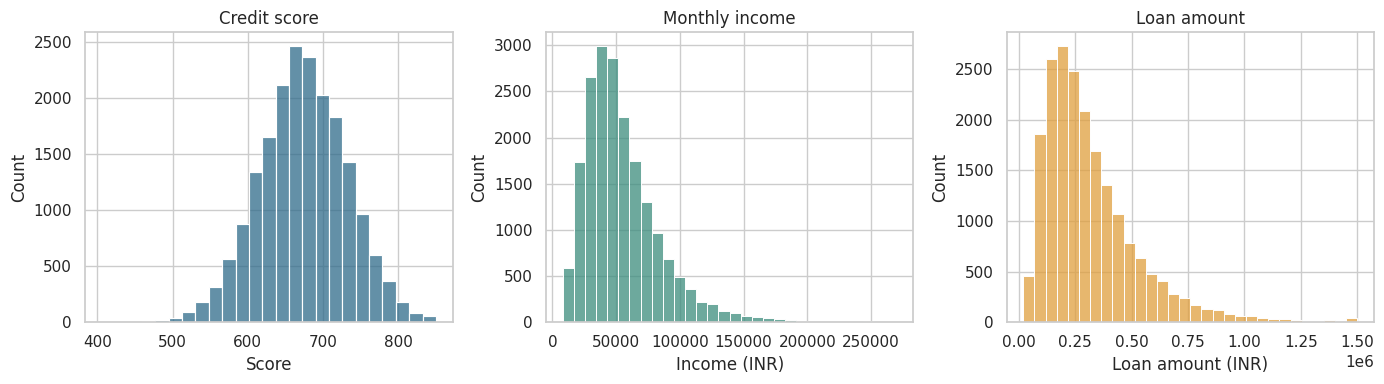

Most common loan purposes:


,applications
loan_purpose,
Personal,7036
Vehicle,3461
Home improvement,3156
Small business,2306
Medical,2033
Education,2008


In [9]:
# ==============================================================================
# STEP 9: UNIVARIATE DISTRIBUTION ANALYSIS
# Inspect histograms of continuous risk predictors (Credit Score, Income, Loan Amount)
# and tabulate the distribution of stated loan purposes.
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Credit Score: Symmetric, bell-shaped distribution across bureau spectrum
sns.histplot(app["credit_score"].dropna(), bins=25, ax=axes[0], color="#2F6B8A")
axes[0].set_title("Credit score")
axes[0].set_xlabel("Score")

# 2. Monthly Income: Right-skewed distribution characteristic of wage distributions
sns.histplot(app["monthly_income"].dropna(), bins=30, ax=axes[1], color="#3C8D7D")
axes[1].set_title("Monthly income")
axes[1].set_xlabel("Income (INR)")

# 3. Loan Amount: Clustered loan sizes with an extended right-side exposure tail
sns.histplot(app["loan_amount"], bins=30, ax=axes[2], color="#E09F3E")
axes[2].set_title("Loan amount")
axes[2].set_xlabel("Loan amount (INR)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "numeric_distributions.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Frequency tabulation of categorical loan purposes
print("Most common loan purposes:")
display(app["loan_purpose"].value_counts().to_frame("applications"))


## 8. Segmented analysis: compare default rates

A rate is more useful than a raw count when groups are different sizes. The following charts compare the share of loans with payment difficulty across credit score bands, DTI bands and employment types.

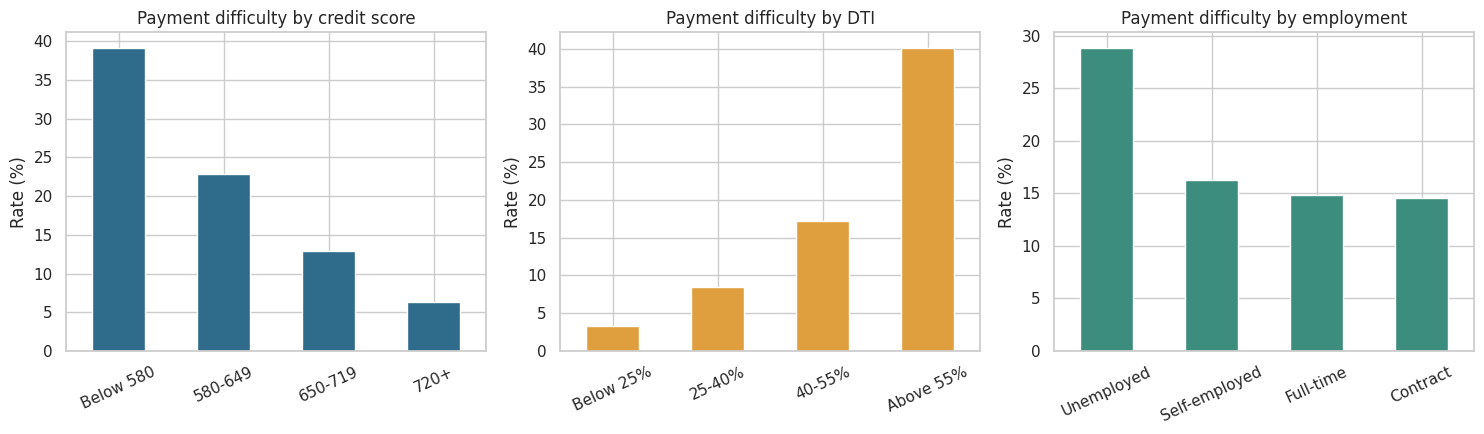

Default rate by credit score band (%):


,default_rate_percent
credit_score_band,
Below 580,39.19
580-649,22.84
650-719,12.95
720+,6.28


Default rate by DTI band (%):


,default_rate_percent
dti_band,
Below 25%,3.33
25-40%,8.47
40-55%,17.14
Above 55%,40.16


Default rate by employment (%):


,default_rate_percent
employment_status,
Unemployed,28.87
Self-employed,16.23
Full-time,14.81
Contract,14.51


In [10]:
# ==============================================================================
# STEP 10: SEGMENTED RISK RATE ANALYSIS ACROSS COHORTS
# Bin continuous variables into intuitive underwriting cohorts and measure
# segmented default rates (%) to eliminate distortion from raw class imbalance.
# ==============================================================================

# Discretize credit score into standard underwriting risk tiers
app["credit_score_band"] = pd.cut(
    app["credit_score"], 
    bins=[0, 580, 650, 720, 900],
    labels=["Below 580", "580-649", "650-719", "720+"]
)

# Discretize Debt-to-Income (DTI) ratio into financial leverage bands
app["dti_band"] = pd.cut(
    app["debt_to_income_ratio"], 
    bins=[-np.inf, 0.25, 0.40, 0.55, np.inf],
    labels=["Below 25%", "25-40%", "40-55%", "Above 55%"]
)

# Compute empirical default probability (in %) within each cohort segment
credit_default_rate = app.groupby("credit_score_band", observed=False)["target_default"].mean() * 100
dti_default_rate = app.groupby("dti_band", observed=False)["target_default"].mean() * 100
employment_default_rate = app.groupby("employment_status")["target_default"].mean().sort_values(ascending=False) * 100

# Plot 3-panel comparative bar charts of default probability across cohorts
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Subplot 1: Default rate by credit score tier (steep monotonic drop)
credit_default_rate.plot(kind="bar", ax=axes[0], color="#2F6B8A")
axes[0].set_title("Payment difficulty by credit score")
axes[0].set_ylabel("Rate (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

# Subplot 2: Default rate by DTI leverage tier (sharp escalation above 55%)
dti_default_rate.plot(kind="bar", ax=axes[1], color="#E09F3E")
axes[1].set_title("Payment difficulty by DTI")
axes[1].set_ylabel("Rate (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

# Subplot 3: Default rate by employment classification (unemployed/contract higher risk)
employment_default_rate.plot(kind="bar", ax=axes[2], color="#3C8D7D")
axes[2].set_title("Payment difficulty by employment")
axes[2].set_ylabel("Rate (%)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "default_rate_segments.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Tabular display of segmented default percentages
print("Default rate by credit score band (%):")
display(credit_default_rate.round(2).to_frame("default_rate_percent"))

print("Default rate by DTI band (%):")
display(dti_default_rate.round(2).to_frame("default_rate_percent"))

print("Default rate by employment (%):")
display(employment_default_rate.round(2).to_frame("default_rate_percent"))


### Bivariate check: loan size and payment difficulty

A box plot compares the distribution of loan amounts for the two outcome groups. The boxes show the middle half of the data; points beyond the whiskers are possible outliers, not necessarily errors.

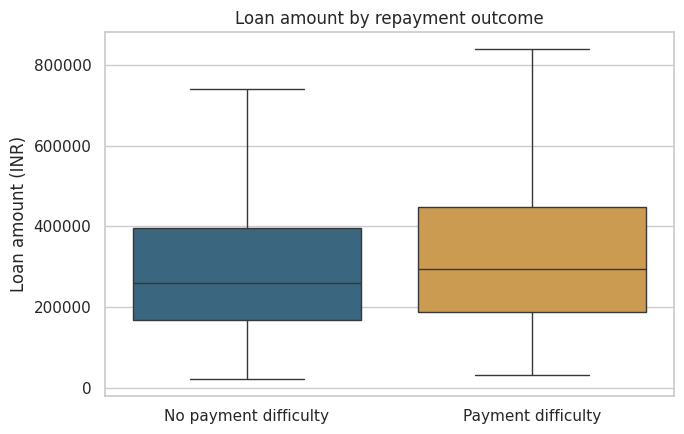

In [11]:
# ==============================================================================
# STEP 11: BIVARIATE LOAN AMOUNT DISTRIBUTION BY OUTCOME
# Compare loan amount medians and interquartile spreads between defaulting
# and non-defaulting borrowers using a boxplot without extreme fliers.
# ==============================================================================

plt.figure(figsize=(7, 4.5))

# Boxplot comparing loan amount distributions by repayment outcome
sns.boxplot(
    data=app, x="target_default", y="loan_amount", hue="target_default", legend=False,
    palette={0: "#2F6B8A", 1: "#E09F3E"}, showfliers=False
)
plt.xticks([0, 1], ["No payment difficulty", "Payment difficulty"])
plt.xlabel("")
plt.ylabel("Loan amount (INR)")
plt.title("Loan amount by repayment outcome")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "loan_amount_by_outcome.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()


## 9. Correlation and probability checks

Correlation shows linear relationships between numeric variables. It does not prove cause and effect. Following the assignment brief, we calculate the strongest numeric feature-pair correlations separately for applicants with and without payment difficulty. The target field is not included in those pair lists.

Top feature-pair correlations: no payment difficulty


,feature_1,feature_2,absolute_correlation
0,age,employment_years,0.862
1,monthly_income,loan_amount,0.810
2,loan_amount,monthly_installment,0.744
3,credit_score,interest_rate_pct,0.720
4,monthly_income,monthly_installment,0.634
5,monthly_income,existing_monthly_debt,0.621
6,loan_amount,loan_to_annual_income_ratio,0.514
7,existing_monthly_debt,loan_amount,0.495
8,existing_monthly_debt,debt_to_income_ratio,0.483
9,loan_term_months,monthly_installment,0.466


Top feature-pair correlations: payment difficulty


,feature_1,feature_2,absolute_correlation
0,age,employment_years,0.861
1,monthly_income,loan_amount,0.822
2,credit_score,interest_rate_pct,0.734
3,loan_amount,monthly_installment,0.712
4,monthly_income,existing_monthly_debt,0.675
5,loan_term_months,debt_to_income_ratio,0.615
6,monthly_installment,debt_to_income_ratio,0.602
7,monthly_income,monthly_installment,0.587
8,loan_term_months,monthly_installment,0.541
9,existing_monthly_debt,loan_amount,0.515


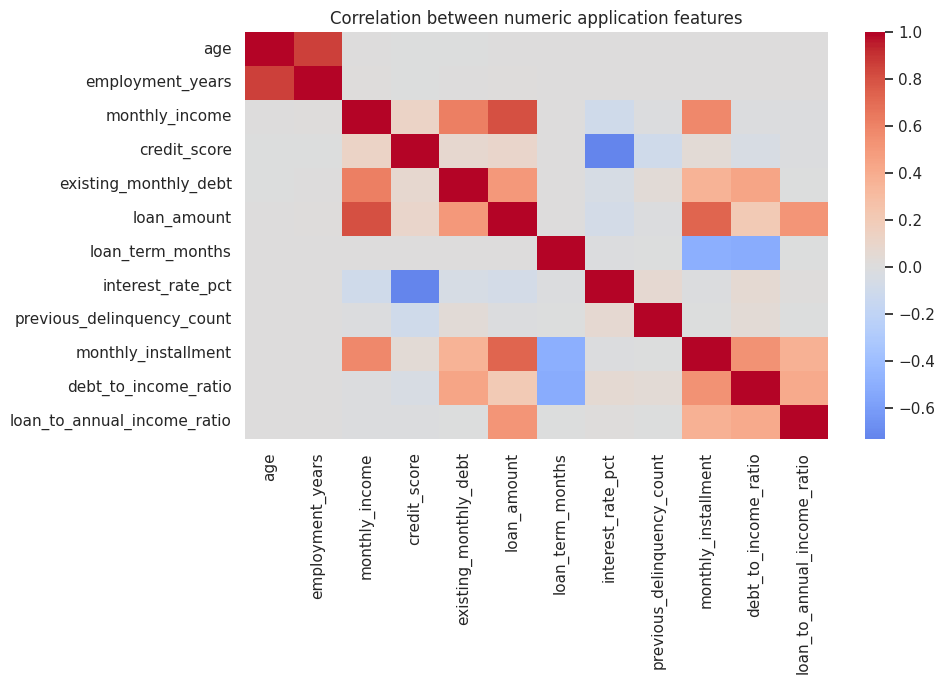

P(payment difficulty): 0.158
P(payment difficulty | any previous delinquency): 0.261
P(payment difficulty | no previous delinquency): 0.152


In [12]:
# ==============================================================================
# STEP 12: SEGMENTED CORRELATION ANALYSIS (TARGET=0 VS TARGET=1)
# Compute feature correlation matrices separately for each target class.
# Identify the top 10 intra-class feature pair correlations to detect structural shifts.
# ==============================================================================

# Continuous numeric features evaluated for linear relationships
numeric_features = [
    "age", "employment_years", "monthly_income", "credit_score", "existing_monthly_debt",
    "loan_amount", "loan_term_months", "interest_rate_pct", "previous_delinquency_count",
    "monthly_installment", "debt_to_income_ratio", "loan_to_annual_income_ratio"
]

def top_correlations_for_group(frame, columns, top_n=10):
    """
    Computes Pearson correlation matrix, unrolls upper triangle to exclude identity
    and duplicates, and returns top N absolute feature correlations.
    """
    corr = frame[columns].corr(numeric_only=True).abs()
    # Mask diagonal and lower triangle using upper triangle Boolean indexing
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    # Stack and sort by absolute correlation strength in descending order
    pairs = upper.stack().sort_values(ascending=False).head(top_n)
    result = pairs.reset_index()
    result.columns = ["feature_1", "feature_2", "absolute_correlation"]
    return result

# Compute isolated top 10 correlations for non-defaulters vs defaulters
corr_no_difficulty = top_correlations_for_group(app[app["target_default"] == 0], numeric_features)
corr_with_difficulty = top_correlations_for_group(app[app["target_default"] == 1], numeric_features)

print("Top feature-pair correlations: no payment difficulty")
display(corr_no_difficulty.round(3))

print("Top feature-pair correlations: payment difficulty")
display(corr_with_difficulty.round(3))

# Full correlation heatmap across all continuous features
plt.figure(figsize=(10, 7))
sns.heatmap(app[numeric_features].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between numeric application features")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "correlation_heatmap.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------------------------
# Driver Verification: Empirical Conditional Probabilities for Prior Delinquencies
# P(Default | Delinquent) vs P(Default | Clean)
# ------------------------------------------------------------------------------
prob_default_overall = app["target_default"].mean()
prob_default_if_prior_delinquency = app.loc[app["previous_delinquency_count"] > 0, "target_default"].mean()
prob_default_if_no_prior_delinquency = app.loc[app["previous_delinquency_count"] == 0, "target_default"].mean()

print(f"P(payment difficulty): {prob_default_overall:.3f}")
print(f"P(payment difficulty | any previous delinquency): {prob_default_if_prior_delinquency:.3f}")
print(f"P(payment difficulty | no previous delinquency): {prob_default_if_no_prior_delinquency:.3f}")


## 10. Basic statistical test

We compare the average credit score of the two outcome groups with a Welch two-sample t-test. The test checks whether the group means differ beyond what might be expected from sample variation. A small p-value is not a measure of business importance and does not show that credit score causes default.

In [13]:
# ==============================================================================
# STEP 13: STATISTICAL HYPOTHESIS TESTING (WELCH'S T-TEST)
# Test whether the difference in mean credit score between defaulters and
# non-defaulters is statistically significant (H0: mu_default = mu_nondefault).
# Welch's t-test is employed because sample sizes and variances are unequal.
# ==============================================================================

# Extract credit score observations partitioned by target default status
score_default = app.loc[app["target_default"] == 1, "credit_score"].dropna()
score_nondefault = app.loc[app["target_default"] == 0, "credit_score"].dropna()

# Perform two-sided Welch's t-test (equal_var=False)
t_stat, p_value = ttest_ind(score_default, score_nondefault, equal_var=False)

print("Mean credit score - payment difficulty:", round(score_default.mean(), 2))
print("Mean credit score - no payment difficulty:", round(score_nondefault.mean(), 2))
print("Welch t-statistic:", round(t_stat, 3))
print("p-value:", f"{p_value:.6g}")

# Evaluate hypothesis test against conventional 5% significance threshold
if p_value < 0.05:
    print("At the 5% level, the sample provides evidence that the two group means differ.")
else:
    print("At the 5% level, there is not enough evidence of a difference in the two means.")


Mean credit score - payment difficulty: 642.88
Mean credit score - no payment difficulty: 679.44
Welch t-statistic: -32.776
p-value: 1.04195e-210
At the 5% level, the sample provides evidence that the two group means differ.


## 11. Previous applications and repayment operations

Past application status can help the operations team understand what happened before a loan was booked. The instalment table is post-loan monitoring data. It is useful for tracking late payments, but it must **not** be used as an input to the application-time prediction model because that would reveal information from after the decision.

Previous application status summary:


,application_count,late_30_plus_rate
previous_status,,
Approved,16711,3.00
Cancelled,3672,4.96
Refused,2442,16.58
Unused offer,2006,6.28


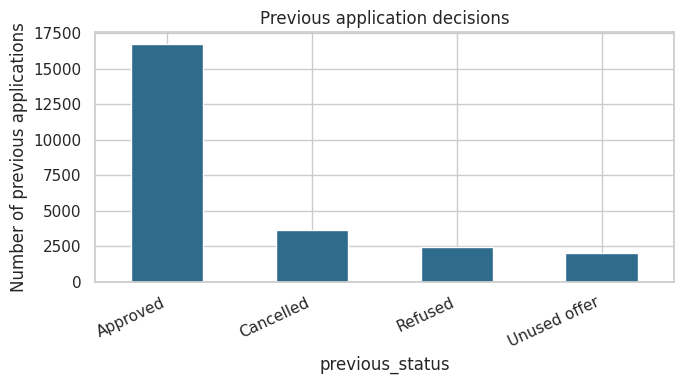

Repayment history status counts:


,installment_count
payment_status,
On time,102077
Late 1-29 days,8951
Late 30+ days,8690
Missed,282


[NOTE] These repayment records happen after loan booking, so they are for portfolio monitoring only.


In [14]:
# ==============================================================================
# STEP 14: HISTORICAL APPLICATION DECISION & DELINQUENCY ANALYSIS
# Analyze historical loan applications: approval/rejection rates and historical
# 30+ DPD delinquency incidence to uncover systemic underwriter patterns.
# ==============================================================================

# Group historical applications by past status and compute 30+ DPD incidence
previous_summary = previous_applications.groupby("previous_status").agg(
    application_count=("previous_application_id", "count"),
    late_30_plus_rate=("days_past_due", lambda x: (x >= 30).mean() * 100)
).sort_values("application_count", ascending=False)
previous_summary["late_30_plus_rate"] = previous_summary["late_30_plus_rate"].round(2)

print("Previous application status summary:")
display(previous_summary)

# Visualize application volume breakdown by historical underwriter decision
plt.figure(figsize=(7, 4))
previous_summary["application_count"].plot(kind="bar", color="#2F6B8A")
plt.ylabel("Number of previous applications")
plt.title("Previous application decisions")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "previous_application_status.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Portfolio monitoring: breakdown of installment repayment statuses
repayment_summary = repayment_history.groupby("payment_status").size().sort_values(ascending=False)
print("Repayment history status counts:")
display(repayment_summary.to_frame("installment_count"))
print("[NOTE] These repayment records happen after loan booking, so they are for portfolio monitoring only.")


## 12. Fraud pattern review

This is a separate transaction-level review. We look for patterns linked with the simulated fraud label, such as channel, international status, a new device, and transaction size. These patterns are review signals, not proof that a transaction is fraudulent.

Overall simulated fraud label rate: 1.74%
Fraud label rate by channel (%):


,fraud_rate_percent
channel,
Bank transfer,2.28
Online,2.08
Mobile,1.95
Card present,1.25
ATM,1.13


Fraud label rate by device flag (%):


,fraud_rate_percent
new_device,
Usual device,1.59
New device,4.34


Fraud label rate by international flag (%):


,fraud_rate_percent
is_international,
Domestic,1.57
International,3.86


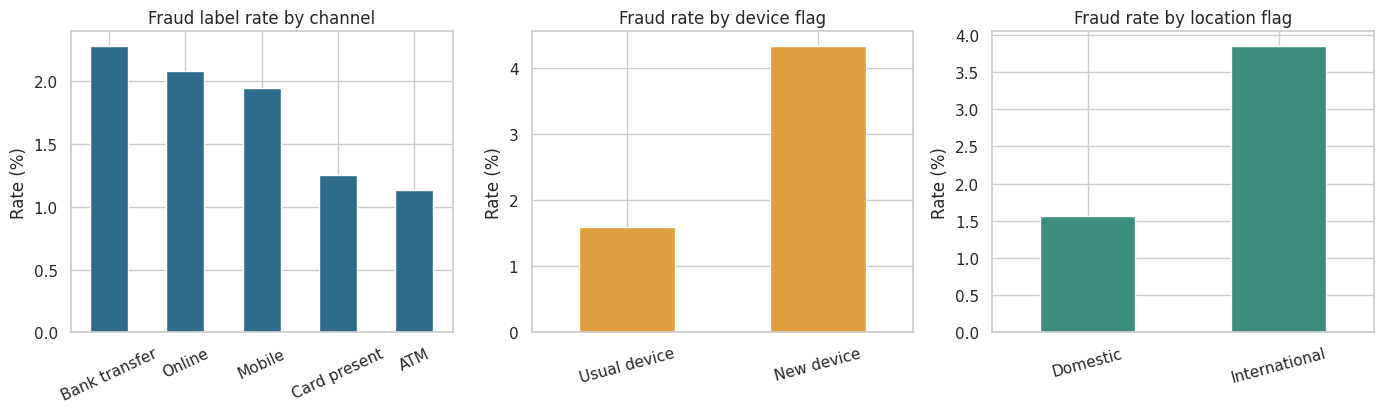

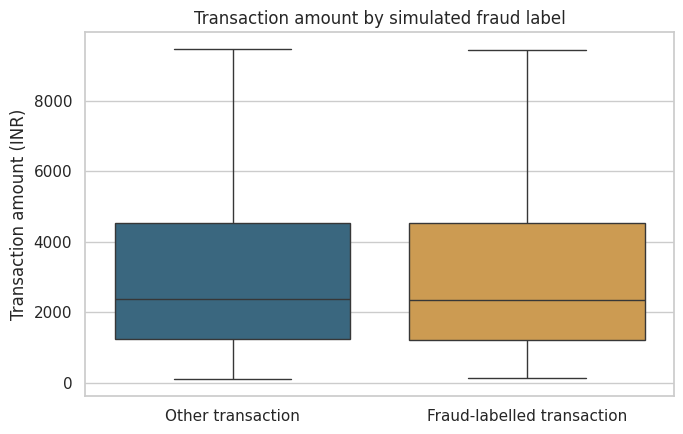

In [15]:
# ==============================================================================
# STEP 15: DIGITAL TRANSACTION BEHAVIOR & FRAUD ANALYTICS
# Quantify fraud incidence rates across digital transaction channels, device flags,
# and international locations to detect high-risk operational attack vectors.
# ==============================================================================

# Baseline synthetic transaction fraud rate
fraud_rate = transactions["target_fraud"].mean() * 100

# Segmented fraud rates across key behavioral risk indicators
fraud_by_channel = transactions.groupby("channel")["target_fraud"].mean().sort_values(ascending=False) * 100
fraud_by_device = transactions.groupby("new_device")["target_fraud"].mean() * 100
fraud_by_international = transactions.groupby("is_international")["target_fraud"].mean() * 100

print(f"Overall simulated fraud label rate: {fraud_rate:.2f}%")
print("Fraud label rate by channel (%):")
display(fraud_by_channel.round(2).to_frame("fraud_rate_percent"))

print("Fraud label rate by device flag (%):")
display(fraud_by_device.rename(index={0: "Usual device", 1: "New device"}).round(2).to_frame("fraud_rate_percent"))

print("Fraud label rate by international flag (%):")
display(fraud_by_international.rename(index={0: "Domestic", 1: "International"}).round(2).to_frame("fraud_rate_percent"))

# 3-panel comparative bar chart visualization of fraud incidence
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

# Panel 1: Fraud rate by digital channel (Online & Mobile lead)
fraud_by_channel.plot(kind="bar", ax=axes[0], color="#2F6B8A")
axes[0].set_title("Fraud label rate by channel")
axes[0].set_ylabel("Rate (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

# Panel 2: Fraud rate by new device flag (strong risk indicator)
fraud_by_device.rename(index={0: "Usual device", 1: "New device"}).plot(kind="bar", ax=axes[1], color="#E09F3E")
axes[1].set_title("Fraud rate by device flag")
axes[1].set_ylabel("Rate (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

# Panel 3: Fraud rate by international location flag
fraud_by_international.rename(index={0: "Domestic", 1: "International"}).plot(kind="bar", ax=axes[2], color="#3C8D7D")
axes[2].set_title("Fraud rate by location flag")
axes[2].set_ylabel("Rate (%)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fraud_patterns.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Boxplot comparing monetary amount between fraud and non-fraud transactions
plt.figure(figsize=(7, 4.5))
sns.boxplot(
    data=transactions, x="target_fraud", y="transaction_amount", hue="target_fraud", legend=False,
    palette={0: "#2F6B8A", 1: "#E09F3E"}, showfliers=False
)
plt.xticks([0, 1], ["Other transaction", "Fraud-labelled transaction"])
plt.xlabel("")
plt.ylabel("Transaction amount (INR)")
plt.title("Transaction amount by simulated fraud label")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "transaction_amount_fraud.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()


## 13. A simple machine-learning baseline for credit risk

We use logistic regression because it is a standard first classification model and is easier to explain than a complex model. Numeric missing values are filled with the **training-set median**, features are scaled using the training set, and the data is split into training and test sets. `stratify=y` keeps the class share similar in both sets.

The features below are available around the time of application. The post-loan repayment history and transaction fraud labels are not included. The 0.50 decision threshold is only a standard starting point; a real risk team would tune it based on cost, capacity and policy.

Baseline logistic regression metrics:


,test_value
Accuracy,0.855
Precision,0.640
Recall,0.185
F1 score,0.287
ROC-AUC,0.786



Confusion matrix (rows = actual, columns = predicted):


,Predicted 0,Predicted 1
Actual 0,4127,82
Actual 1,645,146



Classification report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.92      4209
           1       0.64      0.18      0.29       791

    accuracy                           0.85      5000
   macro avg       0.75      0.58      0.60      5000
weighted avg       0.83      0.85      0.82      5000



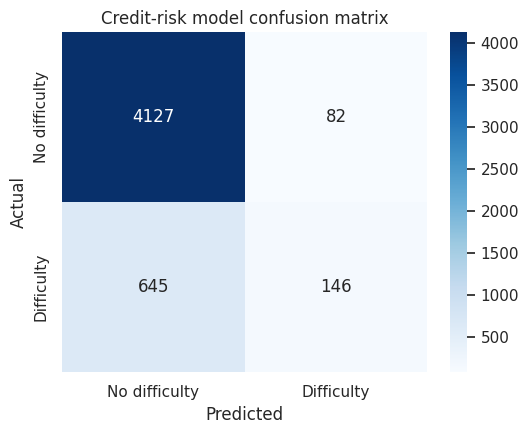

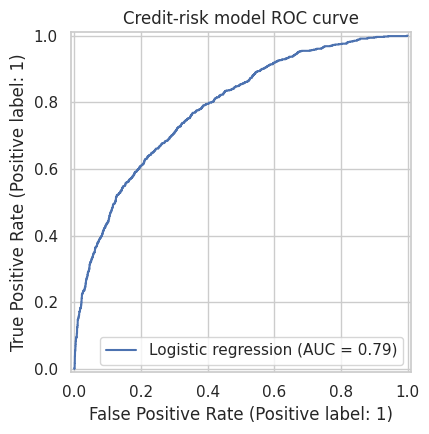

Model coefficients (direction only; not causal effects):


,scaled_coefficient
monthly_income,-1.494
credit_score,-0.683
loan_term_months,-0.610
employment_years,0.001
interest_rate_pct,0.077
previous_delinquency_count,0.097
existing_monthly_debt,0.750
loan_amount,0.983


In [16]:
# ==============================================================================
# STEP 16: BASELINE CREDIT RISK MODELING (STRATIFIED LOGISTIC REGRESSION)
# Train an interpretable baseline classifier to estimate default probabilities:
# 1. Stratified Train/Test Split (75% train / 25% test) preserving default ratio
# 2. Median imputation learned strictly on training fold (prevent data leakage)
# 3. StandardScaler normalization for feature standardization
# 4. Multi-metric evaluation: Accuracy, Precision, Recall, F1, and ROC-AUC
# ==============================================================================

# Core feature set available at loan application decision time
feature_columns = [
    "credit_score", "monthly_income", "employment_years", "loan_amount",
    "loan_term_months", "interest_rate_pct", "previous_delinquency_count",
    "existing_monthly_debt"
]
X = app[feature_columns].copy()
y = app["target_default"].astype(int)

# Stratified partition to preserve the 8.8:1 target class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

# Learn column medians on training data ONLY, then impute both train and test sets
train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Standardize continuous features to mean=0, variance=1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train baseline Logistic Regression classifier
model = LogisticRegression(max_iter=1000, random_state=SEED)
model.fit(X_train_scaled, y_train)

# Predict binary outcomes and continuous posterior probabilities on held-out test data
y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]

# Tabulate comprehensive classification performance metrics
model_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
})
print("Baseline logistic regression metrics:")
display(model_metrics.round(3).to_frame("test_value"))

# Generate and display confusion matrix
print("\nConfusion matrix (rows = actual, columns = predicted):")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix heatmap visualization
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", 
    xticklabels=["No difficulty", "Difficulty"],
    yticklabels=["No difficulty", "Difficulty"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Credit-risk model confusion matrix")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "model_confusion_matrix.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Plot Receiver Operating Characteristic (ROC) curve
fig, ax = plt.subplots(figsize=(6, 4.5))
RocCurveDisplay.from_predictions(y_test, y_probability, ax=ax, name="Logistic regression")
ax.set_title("Credit-risk model ROC curve")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "model_roc_curve.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close()

# Extract and rank standardized coefficients to inspect feature directionality
coefficients = pd.Series(model.coef_[0], index=feature_columns).sort_values()
print("Model coefficients (direction only; not causal effects):")
display(coefficients.to_frame("scaled_coefficient").round(3))


## 14. Linear algebra connection

Logistic regression uses a weighted sum of input features before converting that score into a probability. A matrix contains rows of applicant features; the model coefficients form a weight vector. The dot product gives the linear score. This small check shows the shapes and the calculation directly.

In [17]:
# ==============================================================================
# STEP 17: LINEAR ALGEBRA CONNECTION (MATRIX-VECTOR FORMULATION)
# Demonstrate the underlying linear algebraic scoring equation:
# z = X @ w + b (where z is log-odds, mapped to probability via sigmoid function)
# ==============================================================================

# Extract a 5-applicant sub-matrix from the test feature array (5 x 8)
sample_matrix = X_test_scaled[:5]

# Extract the trained model coefficient vector (8 x 1)
weight_vector = model.coef_[0]

# Compute matrix-vector product plus bias scalar: z = Xw + b
linear_score = sample_matrix @ weight_vector + model.intercept_[0]

print("Sample feature matrix shape:", sample_matrix.shape)
print("Coefficient vector shape:", weight_vector.shape)
print("Linear score values (log-odds z):", np.round(linear_score, 3))
print("The model turns each linear score into a probability using the logistic function: p = 1 / (1 + exp(-z)).")


Sample feature matrix shape: (5, 8)
Coefficient vector shape: (8,)
Linear score values: [-2.214 -2.571 -4.679 -1.15  -2.784]
The model turns each linear score into a probability using the logistic function.


## 15. Simple financial-risk calculation

A common starting point for expected credit loss is:

**Expected Loss = Probability of Default x Exposure at Default x Loss Given Default**

For this practice project, exposure is represented by requested loan amount and Loss Given Default (LGD) is assumed to be 45%. This is only an example assumption. The predicted probability is not a final bank decision and should not be used to automatically approve or reject a real customer.

In [18]:
# ==============================================================================
# STEP 18: FINANCIAL EXPECTED CREDIT LOSS (ECL) & UNDERWRITING POLICY
# Compute individual and portfolio expected loss using the Basel / IFRS 9 standard:
# Expected Loss (EL) = Probability of Default (PD) * Exposure at Default (EAD) * Loss Given Default (LGD)
# Establish a manual underwriter review policy at a 20% default probability cutoff.
# ==============================================================================

# Standard Basel III retail portfolio loss given default assumption (45%)
LGD_ASSUMPTION = 0.45

# Decision policy cut-off: flag applications with predicted default probability >= 20%
review_threshold = 0.20  # Example operational threshold for manual underwriting review

# Assemble test-set scoring table
risk_results = app.loc[X_test.index, ["applicant_id", "loan_amount", "target_default"]].copy()
risk_results["predicted_default_probability"] = y_probability

# Calculate financial expected loss per applicant: EL = PD * EAD * LGD
risk_results["expected_loss_estimate"] = (
    risk_results["predicted_default_probability"] * risk_results["loan_amount"] * LGD_ASSUMPTION
)

# Apply policy rule: Flag for manual underwriting review
risk_results["manual_review_flag"] = risk_results["predicted_default_probability"] >= review_threshold

# Compute key portfolio-level risk and review economics metrics
review_share = risk_results["manual_review_flag"].mean() * 100
observed_default_rate_test = risk_results["target_default"].mean() * 100
flagged_default_rate = risk_results.loc[risk_results["manual_review_flag"], "target_default"].mean() * 100
portfolio_expected_loss = risk_results["expected_loss_estimate"].sum()
mean_expected_loss = risk_results["expected_loss_estimate"].mean()

economics_summary = pd.Series({
    "Test-set applications": len(risk_results),
    "Test-set observed payment difficulty rate (%)": observed_default_rate_test,
    "Manual-review share at 20% score threshold (%)": review_share,
    "Observed payment difficulty rate in flagged group (%)": flagged_default_rate,
    "Assumed LGD (%)": LGD_ASSUMPTION * 100,
    "Mean estimated loss per tested application (INR)": mean_expected_loss,
    "Total estimated loss across test set (INR)": portfolio_expected_loss
})
display(economics_summary.to_frame("value").round(2))
print("[CAUTION] The 20% score line is a made-up practice threshold. Check review capacity, missed defaults and wrongly flagged customers before setting any real policy.")

# Save a sample scored subset (500 records) to CSV for operational reporting
risk_results.head(500).to_csv(DATA_DIR / "sample_scored_applications.csv", index=False)
print("[INFO] Saved a 500-row scored sample to data/sample_scored_applications.csv")


,value
Test-set applications,5.000000e+03
Test-set observed payment difficulty rate (%),1.582000e+01
Manual-review share at 20% score threshold (%),2.748000e+01
Observed payment difficulty rate in flagged group (%),3.574000e+01
Assumed LGD (%),4.500000e+01
Mean estimated loss per tested application (INR),2.534829e+04
Total estimated loss across test set (INR),1.267414e+08


[CAUTION] The 20% score line is a made-up practice threshold. Check review capacity, missed defaults and wrongly flagged customers before setting any real policy.
[INFO] Saved a 500-row scored sample to data/sample_scored_applications.csv


## 16. Main findings and practical recommendations

Use the results printed above to form a short stakeholder summary. These are suitable next steps for a learning project, not approved lending policy.

1. Review credit score, debt burden and previous delinquency together rather than relying on one field.
2. Report default rates as percentages as well as counts because the target is imbalanced.
3. Keep high-value observations until they have been checked; do not remove them just because an IQR rule flags them.
4. Use the baseline model as a comparison point. Evaluate recall, precision and ROC-AUC in addition to accuracy.
5. Keep post-loan repayment records and transaction fraud labels out of application-time model features to avoid information leakage.
6. For fraud monitoring, review transactions with a combination of signals such as new device, international status, channel and amount. Do not treat one signal as proof of fraud.
7. Before any real use, validate the model on a real, representative time-based holdout, check fairness and stability, and have a human risk team approve any action.

### Scope boundary
This project stops at EDA, basic statistical checks, a baseline logistic-regression model, a simple expected-loss calculation and transparent review signals. It does not include production deployment, advanced algorithms, real customer data, real credit bureau data, or a final lending policy.